 City Water Network Monitoring and Leak Detection


In [0]:
%sql
SELECT current_catalog(), current_schema();

current_catalog(),current_schema()
workspace,default


In [0]:
%sql
CREATE VOLUME IF NOT EXISTS workspace.default.assessment_files;

In [0]:
dbutils.fs.mkdirs("/Volumes/workspace/default/assessment_files/water_network")

True

In [0]:
display(dbutils.fs.ls("/Volumes/workspace/default/assessment_files/water_network"))

[]

In [0]:
dbutils.widgets.text("catalog", "raghul_databricks")

In [0]:
dbutils.widgets.text("catalog", "workspace")

In [0]:
%sql
SHOW TABLES IN workspace.default LIKE 'water_*';


database,tableName,isTemporary


In [0]:
%sql
SELECT table_catalog, table_schema, table_name
FROM system.information_schema.tables
WHERE table_name LIKE 'water_%';

table_catalog,table_schema,table_name


In [0]:
src_dir = "/Volumes/workspace/default/assessment_files"
dst_dir = "/Volumes/workspace/default/assessment_files/water_network"
files = [
    "water_meter_readings.csv",
    "water_zones.json",
    "water_service_requests.csv",
    "water_reading_changes.csv",
    "water_readings_incremental.csv"
]
for f in files:
    dbutils.fs.mv(f"{src_dir}/{f}", f"{dst_dir}/{f}")
display(dbutils.fs.ls(dst_dir))

path,name,size,modificationTime
dbfs:/Volumes/workspace/default/assessment_files/water_network/water_meter_readings.csv,water_meter_readings.csv,11125,1794387347000
dbfs:/Volumes/workspace/default/assessment_files/water_network/water_reading_changes.csv,water_reading_changes.csv,956,1794387349000
dbfs:/Volumes/workspace/default/assessment_files/water_network/water_readings_incremental.csv,water_readings_incremental.csv,1391,1794387350000
dbfs:/Volumes/workspace/default/assessment_files/water_network/water_service_requests.csv,water_service_requests.csv,2662,1794387348000
dbfs:/Volumes/workspace/default/assessment_files/water_network/water_zones.json,water_zones.json,2343,1794387348000


In [0]:
from pyspark.sql import functions as F
from pyspark.sql.types import StructType, StructField, IntegerType, StringType, DoubleType, TimestampType

catalog = "workspace"
schema = "default"
base_path = "/Volumes/workspace/default/assessment_files/water_network"

required = [
    "water_meter_readings.csv", "water_zones.json", "water_service_requests.csv",
    "water_reading_changes.csv", "water_readings_incremental.csv"
]
available = {entry.name.rstrip("/") for entry in dbutils.fs.ls(base_path)}
missing = sorted(set(required) - available)
if missing:
    raise FileNotFoundError(f"Missing data files in {base_path}: {missing}")

def save_delta(df, name):
    (df.write.format("delta")
       .mode("overwrite")
       .option("overwriteSchema", "true")
       .saveAsTable(f"{catalog}.{schema}.{name}"))

print("Files found:", sorted(available))

Files found: ['water_meter_readings.csv', 'water_reading_changes.csv', 'water_readings_incremental.csv', 'water_service_requests.csv', 'water_zones.json']


In [0]:
reading_schema = StructType([
    StructField("reading_id", IntegerType(), True),
    StructField("meter_id", StringType(), True),
    StructField("zone_id", StringType(), True),
    StructField("reading_time", TimestampType(), True),
    StructField("flow_lpm", DoubleType(), True),
    StructField("pressure_bar", DoubleType(), True),
    StructField("chlorine_mg_l", DoubleType(), True),
    StructField("consumption_liters", IntegerType(), True),
    StructField("reading_status", StringType(), True),
    StructField("source_system", StringType(), True),
])

def read_readings(filename):
    return (spark.read.format("csv")
        .option("header", "true")
        .option("timestampFormat", "yyyy-MM-dd HH:mm:ss")
        .schema(reading_schema)
        .load(f"{base_path}/{filename}"))

source = read_readings("water_meter_readings.csv")
save_delta(source, "water_meter_readings_source")
save_delta(source, "water_meter_readings_work")
save_delta(read_readings("water_reading_changes.csv"), "water_reading_changes")
save_delta(read_readings("water_readings_incremental.csv"), "water_readings_incremental_staging")

In [0]:
zone_raw = spark.read.json(f"{base_path}/water_zones.json")
save_delta(zone_raw, "water_zones_raw")

zone_flat = zone_raw.select(
    "zone_id",
    "zone_name",
    F.col("location.city").alias("city"),
    F.col("location.district").alias("district"),
    "zone_type",
    "daily_capacity_liters",
    "active",
    "commissioned_on"
)
save_delta(zone_flat, "water_zones")

In [0]:
request_schema = StructType([
    StructField("request_id", IntegerType(), True),
    StructField("meter_id", StringType(), True),
    StructField("zone_id", StringType(), True),
    StructField("reported_at", TimestampType(), True),
    StructField("issue_type", StringType(), True),
    StructField("priority", StringType(), True),
    StructField("estimated_cost", DoubleType(), True),
    StructField("work_status", StringType(), True),
])

requests = (
    spark.read.option("header", "true")
    .option("timestampFormat", "yyyy-MM-dd HH:mm:ss")
    .schema(request_schema)
    .csv(f"{base_path}/water_service_requests.csv")
)
save_delta(requests, "water_service_requests")

In [0]:
tables = [
    "water_meter_readings_source", "water_meter_readings_work",
    "water_zones_raw", "water_zones", "water_service_requests",
    "water_reading_changes", "water_readings_incremental_staging"
]
for name in tables:
    print(f"{catalog}.{schema}.{name}: {spark.table(f'{catalog}.{schema}.{name}').count()} rows")

workspace.default.water_meter_readings_source: 157 rows
workspace.default.water_meter_readings_work: 157 rows
workspace.default.water_zones_raw: 11 rows
workspace.default.water_zones: 11 rows
workspace.default.water_service_requests: 36 rows
workspace.default.water_reading_changes: 12 rows
workspace.default.water_readings_incremental_staging: 18 rows


Section A: SQL Querying and Filtering

In [0]:
%sql
DESCRIBE TABLE water_meter_readings_source;

col_name,data_type,comment
reading_id,int,null
meter_id,string,null
zone_id,string,null
reading_time,timestamp,null
flow_lpm,double,null
pressure_bar,double,null
chlorine_mg_l,double,null
consumption_liters,int,null
reading_status,string,null
source_system,string,null


In [0]:
%sql
SELECT COUNT(*) AS total_rows FROM water_meter_readings_source;

total_rows
157


In [0]:
%sql
SELECT * FROM water_meter_readings_source LIMIT 10;

reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1001,M001,W01,2026-10-01T07:00:00.000Z,39.1,3.56,0.75,2365,Valid,Gateway
1002,M002,W02,2026-10-01T08:10:00.000Z,59.9,4.6,0.39,3545,Valid,SmartMeter
1003,M003,W03,2026-10-01T09:20:00.000Z,25.7,2.22,1.15,548,Valid,FieldApp
1004,M004,W04,2026-10-01T10:00:00.000Z,56.7,2.84,1.1,2871,Valid,Gateway
1005,M005,W05,2026-10-01T11:10:00.000Z,61.8,3.04,0.43,2656,Suspect,SmartMeter
1006,M006,W06,2026-10-01T12:20:00.000Z,35.8,2.52,1.2,2171,Valid,FieldApp
1007,M007,W07,2026-10-01T13:00:00.000Z,65.0,3.19,0.67,4167,Valid,Gateway
1008,M008,W08,2026-10-01T14:10:00.000Z,70.3,3.39,0.54,3621,Valid,SmartMeter
1009,M009,W09,2026-10-01T15:20:00.000Z,30.8,4.57,1.05,1609,Valid,FieldApp
1010,M010,W10,2026-10-01T16:00:00.000Z,81.3,2.38,0.33,1829,Valid,Gateway


In [0]:
%sql
SELECT reading_id, meter_id, zone_id, reading_time, consumption_liters
FROM water_meter_readings_source
WHERE reading_status = 'Valid';

reading_id,meter_id,zone_id,reading_time,consumption_liters
1001,M001,W01,2026-10-01T07:00:00.000Z,2365
1002,M002,W02,2026-10-01T08:10:00.000Z,3545
1003,M003,W03,2026-10-01T09:20:00.000Z,548
1004,M004,W04,2026-10-01T10:00:00.000Z,2871
1006,M006,W06,2026-10-01T12:20:00.000Z,2171
1007,M007,W07,2026-10-01T13:00:00.000Z,4167
1008,M008,W08,2026-10-01T14:10:00.000Z,3621
1009,M009,W09,2026-10-01T15:20:00.000Z,1609
1010,M010,W10,2026-10-01T16:00:00.000Z,1829
1011,M011,W01,2026-10-02T07:10:00.000Z,313


In [0]:
%sql
SELECT *
FROM water_meter_readings_source
WHERE pressure_bar < 2.5
ORDER BY pressure_bar ASC;

reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1071,M011,W01,2026-10-08T07:10:00.000Z,10.9,1.8,0.8,647,Valid,SmartMeter
1064,M004,W04,2026-10-07T10:00:00.000Z,20.3,1.82,0.84,708,Valid,Gateway
1024,M024,W04,2026-10-03T10:20:00.000Z,44.5,1.83,1.25,2085,Valid,FieldApp
1116,M026,W06,2026-10-12T12:10:00.000Z,28.9,1.84,0.36,1692,Valid,SmartMeter
1133,M013,W03,2026-10-14T09:00:00.000Z,15.6,1.86,0.8,900,Valid,Gateway
1028,M028,W08,2026-10-03T14:00:00.000Z,15.0,1.9,0.94,452,Valid,Gateway
1032,M002,W02,2026-10-04T08:10:00.000Z,34.4,1.92,0.88,1006,Valid,SmartMeter
1051,M021,W01,2026-10-06T07:20:00.000Z,72.0,1.93,0.27,1818,Valid,FieldApp
1052,M022,W02,2026-10-06T08:00:00.000Z,74.0,1.94,0.21,4669,Valid,Gateway
1044,M014,W04,2026-10-05T10:10:00.000Z,79.3,1.95,1.23,2661,Valid,SmartMeter


In [0]:
%sql
SELECT *
FROM water_meter_readings_source
WHERE flow_lpm BETWEEN 20 AND 50
  AND source_system IN ('Gateway', 'SmartMeter');

reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1001,M001,W01,2026-10-01T07:00:00.000Z,39.1,3.56,0.75,2365,Valid,Gateway
1014,M014,W04,2026-10-02T10:10:00.000Z,22.4,4.73,0.5,1108,Valid,SmartMeter
1017,M017,W07,2026-10-02T13:10:00.000Z,28.0,3.77,1.08,1318,Valid,SmartMeter
1019,M019,W09,2026-10-02T15:00:00.000Z,23.0,4.34,0.28,1091,Valid,Gateway
1022,M022,W02,2026-10-03T08:00:00.000Z,32.5,3.35,0.6,1706,Suspect,Gateway
1032,M002,W02,2026-10-04T08:10:00.000Z,34.4,1.92,0.88,1006,Valid,SmartMeter
1047,M017,W07,2026-10-05T13:10:00.000Z,28.8,3.23,0.91,1258,Valid,SmartMeter
1049,M019,W09,2026-10-05T15:00:00.000Z,21.4,2.43,0.47,611,Valid,Gateway
1050,M020,W10,2026-10-05T16:10:00.000Z,37.2,3.91,1.02,2154,Valid,SmartMeter
1056,M026,W06,2026-10-06T12:10:00.000Z,27.2,2.69,0.68,1131,Suspect,SmartMeter


In [0]:
%sql
SELECT DISTINCT reading_status
FROM water_meter_readings_source;

reading_status
Valid
Suspect
Rejected


In [0]:
%sql
SELECT reading_status, COUNT(*) AS reading_count
FROM water_meter_readings_source
GROUP BY reading_status
ORDER BY reading_count DESC;

reading_status,reading_count
Valid,137
Suspect,11
Rejected,9


Section B: Joins, Aggregations and Window Functions


In [0]:
%sql
SELECT z.zone_name, z.district, r.meter_id, r.consumption_liters
FROM water_meter_readings_source r
JOIN water_zones z ON r.zone_id = z.zone_id;

zone_name,district,meter_id,consumption_liters
Old City,Central,M001,2365
Hill View,North,M002,3545
Market District,Central,M003,548
Lake Side,West,M004,2871
University Quarter,East,M005,2656
Industrial Estate,South,M006,2171
Garden Colony,North,M007,4167
Transit Hub,East,M008,3621
Riverfront,West,M009,1609
South Extension,South,M010,1829


In [0]:
%sql
SELECT r.*
FROM water_meter_readings_source r
LEFT ANTI JOIN water_zones z ON r.zone_id = z.zone_id;

reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1154,M999,W99,2026-10-16T11:00:00.000Z,24.5,3.0,0.45,1150,Valid,FieldApp
1156,M012,null,2026-10-16T12:30:00.000Z,28.0,3.1,0.52,870,Valid,Gateway


In [0]:
%sql
SELECT z.zone_id, z.zone_name, z.zone_type
FROM water_zones z
LEFT JOIN water_meter_readings_source r ON z.zone_id = r.zone_id
WHERE r.reading_id IS NULL;

zone_id,zone_name,zone_type
W11,New Development,Mixed


In [0]:
%sql
SELECT r.zone_id,
       z.zone_name,
       SUM(r.consumption_liters) AS total_valid_consumption,
       ROUND(AVG(r.pressure_bar), 2) AS avg_pressure,
       COUNT(*) AS reading_count
FROM water_meter_readings_source r
LEFT JOIN water_zones z ON r.zone_id = z.zone_id
WHERE r.reading_status = 'Valid' AND r.consumption_liters > 0
GROUP BY r.zone_id, z.zone_name
ORDER BY r.zone_id;

zone_id,zone_name,total_valid_consumption,avg_pressure,reading_count
null,null,870,3.1,1
W01,Old City,23107,3.42,13
W02,Hill View,24120,3.31,13
W03,Market District,35665,3.02,13
W04,Lake Side,20781,3.24,14
W05,University Quarter,28717,3.63,14
W06,Industrial Estate,20212,3.16,13
W07,Garden Colony,25104,3.57,13
W08,Transit Hub,33689,2.87,14
W09,Riverfront,20894,3.55,13


In [0]:
%sql
WITH meter_totals AS (
  SELECT z.district, r.meter_id, SUM(r.consumption_liters) AS total_valid_consumption
  FROM water_meter_readings_source r
  JOIN water_zones z ON r.zone_id = z.zone_id
  WHERE r.reading_status = 'Valid' AND r.consumption_liters > 0
  GROUP BY z.district, r.meter_id
)
SELECT district, meter_id, total_valid_consumption,
       RANK() OVER (PARTITION BY district ORDER BY total_valid_consumption DESC) AS consumption_rank
FROM meter_totals
ORDER BY district, consumption_rank;

district,meter_id,total_valid_consumption,consumption_rank
Central,M023,17814,1
Central,M001,11416,2
Central,M003,10447,3
Central,M013,7404,4
Central,M021,7395,5
Central,M011,4296,6
East,M008,14095,1
East,M018,10660,2
East,M025,10536,3
East,M015,9807,4


Section C: PySpark DataFrame Operations

In [0]:
from pyspark.sql import functions as F

readings_df = spark.table("water_meter_readings_source")
zones_df = spark.table("water_zones")
readings_df.printSchema()
zones_df.printSchema()

root
 |-- reading_id: integer (nullable = true)
 |-- meter_id: string (nullable = true)
 |-- zone_id: string (nullable = true)
 |-- reading_time: timestamp (nullable = true)
 |-- flow_lpm: double (nullable = true)
 |-- pressure_bar: double (nullable = true)
 |-- chlorine_mg_l: double (nullable = true)
 |-- consumption_liters: integer (nullable = true)
 |-- reading_status: string (nullable = true)
 |-- source_system: string (nullable = true)

root
 |-- zone_id: string (nullable = true)
 |-- zone_name: string (nullable = true)
 |-- city: string (nullable = true)
 |-- district: string (nullable = true)
 |-- zone_type: string (nullable = true)
 |-- daily_capacity_liters: long (nullable = true)
 |-- active: boolean (nullable = true)
 |-- commissioned_on: string (nullable = true)



In [0]:
high_flow_df = (
    readings_df
    .select("reading_id", "meter_id", "zone_id", "reading_time", "flow_lpm", "reading_status")
    .filter((F.col("reading_status") == "Valid") & (F.col("flow_lpm") >= 60))
    .orderBy(F.col("flow_lpm").desc())
)
display(high_flow_df)

reading_id,meter_id,zone_id,reading_time,flow_lpm,reading_status
1110,M020,W10,2026-10-11T16:10:00.000Z,84.0,Valid
1106,M016,W06,2026-10-11T12:00:00.000Z,83.9,Valid
1083,M023,W03,2026-10-09T09:10:00.000Z,83.9,Valid
1010,M010,W10,2026-10-01T16:00:00.000Z,81.3,Valid
1013,M013,W03,2026-10-02T09:00:00.000Z,80.7,Valid
1078,M018,W08,2026-10-08T14:20:00.000Z,80.7,Valid
1093,M003,W03,2026-10-10T09:20:00.000Z,80.4,Valid
1031,M001,W01,2026-10-04T07:00:00.000Z,80.1,Valid
1123,M003,W03,2026-10-13T09:20:00.000Z,79.7,Valid
1044,M014,W04,2026-10-05T10:10:00.000Z,79.3,Valid


In [0]:
flow_df = readings_df.withColumn(
    "flow_category",
    F.when(F.col("flow_lpm").isNull(), "Unknown")
     .when(F.col("flow_lpm") >= 60, "High")
     .when(F.col("flow_lpm") >= 30, "Medium")
     .otherwise("Low")
)
display(flow_df.groupBy("flow_category").count().orderBy("flow_category"))

flow_category,count
High,45
Low,44
Medium,68


In [0]:
zone_flow_df = (
    readings_df.join(zones_df, "zone_id", "inner")
    .groupBy("zone_type")
    .agg(F.round(F.avg("flow_lpm"), 2).alias("avg_flow_lpm"), F.count("*").alias("readings"))
    .orderBy("zone_type")
)
display(zone_flow_df)

zone_type,avg_flow_lpm,readings
Commercial,56.1,30
Industrial,43.14,16
Institutional,49.33,16
Mixed,38.17,32
Residential,45.16,61


In [0]:
top_zones_df = (
    readings_df
    .filter((F.col("reading_status") == "Valid") & (F.col("consumption_liters") > 0))
    .groupBy("zone_id")
    .agg(F.sum("consumption_liters").alias("total_valid_consumption"))
    .join(zones_df.select("zone_id", "zone_name"), "zone_id")
    .orderBy(F.col("total_valid_consumption").desc())
    .limit(3)
)
display(top_zones_df)

zone_id,total_valid_consumption,zone_name
W03,35665,Market District
W08,33689,Transit Hub
W05,28717,University Quarter


Section D: Data Quality and Cleaning

In [0]:
%sql
SELECT *
FROM water_meter_readings_source
WHERE reading_id IN (
  SELECT reading_id FROM water_meter_readings_source GROUP BY reading_id HAVING COUNT(*) > 1
)
ORDER BY reading_id, reading_time;

reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1044,M014,W04,2026-10-05T10:10:00.000Z,79.3,1.95,1.23,2661,Valid,SmartMeter
1044,M014,W04,2026-10-16T13:00:00.000Z,36.0,3.2,0.8,1300,Valid,Gateway


In [0]:
%sql
SELECT SUM(CASE WHEN pressure_bar IS NULL THEN 1 ELSE 0 END) AS missing_pressure,
       SUM(CASE WHEN source_system IS NULL THEN 1 ELSE 0 END) AS missing_source_system,
       SUM(CASE WHEN pressure_bar IS NULL OR source_system IS NULL THEN 1 ELSE 0 END) AS affected_rows
FROM water_meter_readings_source;

missing_pressure,missing_source_system,affected_rows
1,1,2


In [0]:
%sql
SELECT * FROM water_meter_readings_source
WHERE pressure_bar IS NULL OR source_system IS NULL;

reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1153,M020,W10,2026-10-16T10:00:00.000Z,31.4,null,0.71,1020,Valid,Gateway
1155,M006,W06,2026-10-16T12:00:00.000Z,44.0,2.9,2.95,1560,Suspect,null


In [0]:
%sql
SELECT reading_id, meter_id, zone_id, flow_lpm, consumption_liters, reading_status,
       CASE WHEN flow_lpm < 0 THEN 'Negative flow'
            WHEN consumption_liters <= 0 THEN 'Nonpositive consumption'
            WHEN zone_id IS NULL THEN 'Missing zone_id'
       END AS issue
FROM water_meter_readings_source
WHERE flow_lpm < 0 OR consumption_liters <= 0 OR zone_id IS NULL;

reading_id,meter_id,zone_id,flow_lpm,consumption_liters,reading_status,issue
1151,M004,W04,-12.5,500,Suspect,Negative flow
1152,M015,W05,22.0,0,Valid,Nonpositive consumption
1156,M012,null,28.0,870,Valid,Missing zone_id


In [0]:
%sql
CREATE OR REPLACE TABLE water_readings_clean
USING DELTA
AS
SELECT reading_id, meter_id, zone_id, reading_time, flow_lpm, pressure_bar,
       chlorine_mg_l, consumption_liters, reading_status, source_system
FROM (
  SELECT *, ROW_NUMBER() OVER (PARTITION BY reading_id ORDER BY reading_time DESC) AS rn
  FROM water_meter_readings_source
)
WHERE rn = 1
  AND reading_status = 'Valid'
  AND flow_lpm > 0
  AND pressure_bar > 0
  AND chlorine_mg_l > 0
  AND consumption_liters > 0
  AND zone_id IS NOT NULL;

num_affected_rows,num_inserted_rows


In [0]:
%sql
SELECT COUNT(*) AS clean_rows, COUNT(DISTINCT reading_id) AS distinct_ids FROM water_readings_clean;

clean_rows,distinct_ids
133,133


In [0]:
%sql
WITH high_requests AS (
  SELECT zone_id, COUNT(*) AS high_priority_requests
  FROM water_service_requests
  WHERE priority = 'High'
  GROUP BY zone_id
),
zone_pressure AS (
  SELECT zone_id, ROUND(AVG(pressure_bar), 2) AS avg_pressure
  FROM water_meter_readings_source
  WHERE pressure_bar IS NOT NULL
  GROUP BY zone_id
)
SELECT h.zone_id, z.zone_name, h.high_priority_requests, p.avg_pressure
FROM high_requests h
JOIN zone_pressure p ON h.zone_id = p.zone_id
JOIN water_zones z ON h.zone_id = z.zone_id
ORDER BY p.avg_pressure;

zone_id,zone_name,high_priority_requests,avg_pressure
W08,Transit Hub,1,2.92
W03,Market District,1,3.18
W06,Industrial Estate,1,3.23
W04,Lake Side,1,3.28
W02,Hill View,2,3.36
W07,Garden Colony,1,3.37
W01,Old City,2,3.44
W05,University Quarter,1,3.5
W09,Riverfront,1,3.6
W10,South Extension,1,3.71


Section E: Delta Lake Tables and CRUD

In [0]:
%sql
CREATE OR REPLACE TABLE water_readings_work_copy
USING DELTA
AS SELECT * FROM water_meter_readings_work;

num_affected_rows,num_inserted_rows


In [0]:
%sql
SELECT COUNT(*) AS total_rows FROM water_readings_work_copy;

total_rows
157


In [0]:
%sql
INSERT INTO water_readings_work_copy VALUES
(1301, 'M001', 'W01', TIMESTAMP '2026-10-17 07:00:00', 41.5, 3.4, 0.80, 1850, 'Valid', 'Gateway'),
(1302, 'M013', 'W03', TIMESTAMP '2026-10-17 08:00:00', 55.2, 3.1, 0.75, 2400, 'Valid', 'SmartMeter');

num_affected_rows,num_inserted_rows
2,2


In [0]:
%sql
SELECT * FROM water_readings_work_copy WHERE reading_id IN (1301, 1302);

reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1301,M001,W01,2026-10-17T07:00:00.000Z,41.5,3.4,0.8,1850,Valid,Gateway
1302,M013,W03,2026-10-17T08:00:00.000Z,55.2,3.1,0.75,2400,Valid,SmartMeter


In [0]:
%sql
UPDATE water_readings_work_copy
SET reading_status = 'Rejected'
WHERE reading_id = 1151 AND reading_status = 'Suspect';

num_affected_rows
1


In [0]:
%sql
SELECT reading_id, flow_lpm, reading_status FROM water_readings_work_copy WHERE reading_id = 1151;

reading_id,flow_lpm,reading_status
1151,-12.5,Rejected


In [0]:
%sql
SELECT reading_status, COUNT(*) AS rows_count
FROM water_readings_work_copy
GROUP BY reading_status
ORDER BY reading_status;

reading_status,rows_count
Rejected,10
Suspect,10
Valid,139


In [0]:
%sql
DELETE FROM water_readings_work_copy
WHERE reading_status = 'Rejected';

num_affected_rows
10


In [0]:
%sql
SELECT reading_status, COUNT(*) AS rows_count
FROM water_readings_work_copy
GROUP BY reading_status
ORDER BY reading_status;

reading_status,rows_count
Suspect,10
Valid,139


In [0]:
from pyspark.sql import functions as F

zone_summary_df = (
    spark.table("water_meter_readings_source")
    .filter((F.col("reading_status") == "Valid") & (F.col("consumption_liters") > 0))
    .join(spark.table("water_zones"), "zone_id", "inner")
    .groupBy("zone_id", "zone_name", "district", "zone_type")
    .agg(
        F.sum("consumption_liters").alias("total_valid_consumption"),
        F.round(F.avg("pressure_bar"), 2).alias("avg_pressure"),
        F.count("*").alias("reading_count")
    )
    .orderBy("zone_id")
)
zone_summary_df.write.format("delta").mode("overwrite").saveAsTable("zone_consumption_summary")
display(spark.table("zone_consumption_summary"))

zone_id,zone_name,district,zone_type,total_valid_consumption,avg_pressure,reading_count
W01,Old City,Central,Residential,23107,3.42,13
W02,Hill View,North,Residential,24120,3.31,13
W03,Market District,Central,Commercial,35665,3.02,13
W04,Lake Side,West,Mixed,20781,3.24,14
W05,University Quarter,East,Institutional,28717,3.63,14
W06,Industrial Estate,South,Industrial,20212,3.16,13
W07,Garden Colony,North,Residential,25104,3.57,13
W08,Transit Hub,East,Commercial,33689,2.87,14
W09,Riverfront,West,Mixed,20894,3.55,13
W10,South Extension,South,Residential,27808,3.72,14


Section F: MERGE, UPSERT and SCD

In [0]:
%sql
SELECT c.*
FROM water_reading_changes c
LEFT SEMI JOIN water_meter_readings_work w ON c.reading_id = w.reading_id
ORDER BY c.reading_id;

reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1005,M005,W05,2026-10-01T11:10:00.000Z,64.3,3.24,0.43,2776,Valid,FieldApp
1027,M027,W07,2026-10-03T13:20:00.000Z,54.6,4.99,0.95,2678,Valid,FieldApp
1062,M002,W02,2026-10-07T08:10:00.000Z,30.1,2.43,0.3,1057,Valid,FieldApp
1088,M028,W08,2026-10-09T14:00:00.000Z,81.4,2.17,1.06,4931,Valid,FieldApp
1119,M029,W09,2026-10-12T15:10:00.000Z,22.1,3.63,1.13,1339,Valid,FieldApp
1145,M025,W05,2026-10-15T11:00:00.000Z,77.5,3.96,1.29,4908,Valid,FieldApp


In [0]:
%sql
SELECT c.*
FROM water_reading_changes c
LEFT ANTI JOIN water_meter_readings_work w ON c.reading_id = w.reading_id
ORDER BY c.reading_id;

reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1201,M002,W02,2026-10-18T08:00:00.000Z,24.0,2.6,0.45,1100,Valid,FieldApp
1202,M005,W05,2026-10-18T09:00:00.000Z,28.7,2.7,0.5,1250,Valid,FieldApp
1203,M008,W08,2026-10-18T10:00:00.000Z,33.4,2.8,0.55,1400,Valid,FieldApp
1204,M011,W01,2026-10-18T11:00:00.000Z,38.1,2.9,0.6,1550,Valid,FieldApp
1205,M014,W04,2026-10-18T12:00:00.000Z,42.8,3.0,0.65,1700,Valid,FieldApp
1206,M017,W07,2026-10-18T13:00:00.000Z,47.5,3.1,0.7,1850,Valid,FieldApp


In [0]:
%sql
MERGE INTO water_meter_readings_work AS t
USING water_reading_changes AS s
ON t.reading_id = s.reading_id
WHEN MATCHED THEN UPDATE SET *
WHEN NOT MATCHED THEN INSERT *;

num_affected_rows,num_updated_rows,num_deleted_rows,num_inserted_rows
12,6,0,6


In [0]:
%sql
SELECT * FROM water_reading_changes
EXCEPT
SELECT * FROM water_meter_readings_work;

reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system


In [0]:
%sql
SELECT * FROM water_meter_readings_work
WHERE reading_id IN (1005, 1027, 1062, 1088, 1119, 1145)
ORDER BY reading_id;

reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1005,M005,W05,2026-10-01T11:10:00.000Z,64.3,3.24,0.43,2776,Valid,FieldApp
1027,M027,W07,2026-10-03T13:20:00.000Z,54.6,4.99,0.95,2678,Valid,FieldApp
1062,M002,W02,2026-10-07T08:10:00.000Z,30.1,2.43,0.3,1057,Valid,FieldApp
1088,M028,W08,2026-10-09T14:00:00.000Z,81.4,2.17,1.06,4931,Valid,FieldApp
1119,M029,W09,2026-10-12T15:10:00.000Z,22.1,3.63,1.13,1339,Valid,FieldApp
1145,M025,W05,2026-10-15T11:00:00.000Z,77.5,3.96,1.29,4908,Valid,FieldApp


In [0]:
%sql
SELECT * FROM water_meter_readings_work
WHERE reading_id IN (1201, 1202, 1203, 1204, 1205, 1206)
ORDER BY reading_id;

reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1201,M002,W02,2026-10-18T08:00:00.000Z,24.0,2.6,0.45,1100,Valid,FieldApp
1202,M005,W05,2026-10-18T09:00:00.000Z,28.7,2.7,0.5,1250,Valid,FieldApp
1203,M008,W08,2026-10-18T10:00:00.000Z,33.4,2.8,0.55,1400,Valid,FieldApp
1204,M011,W01,2026-10-18T11:00:00.000Z,38.1,2.9,0.6,1550,Valid,FieldApp
1205,M014,W04,2026-10-18T12:00:00.000Z,42.8,3.0,0.65,1700,Valid,FieldApp
1206,M017,W07,2026-10-18T13:00:00.000Z,47.5,3.1,0.7,1850,Valid,FieldApp


In [0]:
from delta.tables import DeltaTable
from pyspark.sql import functions as F

spark.table("water_meter_readings_source").write.format("delta").mode("overwrite").saveAsTable("water_readings_merge_api")

target = DeltaTable.forName(spark, "water_readings_merge_api")
changes_df = spark.table("water_reading_changes")

(
    target.alias("t")
    .merge(changes_df.alias("s"), "t.reading_id = s.reading_id")
    .whenMatchedUpdateAll()
    .whenNotMatchedInsertAll()
    .execute()
)

print(spark.table("water_readings_merge_api").count())
display(target.history().select("version", "operation", "operationMetrics"))
display(
    spark.table("water_readings_merge_api")
    .filter(F.col("reading_id").isin(1005, 1027, 1062, 1088, 1119, 1145, 1201, 1202, 1203, 1204, 1205, 1206))
    .orderBy("reading_id")
)

163


version,operation,operationMetrics
1,MERGE,"Map(numTargetRowsCopied -> 0, numTargetRowsDeleted -> 0, numTargetFilesAdded -> 1, numTargetBytesAdded -> 3414, numTargetBytesRemoved -> 0, numTargetDeletionVectorsAdded -> 1, numTargetRowsMatchedUpdated -> 6, executionTimeMs -> 2534, materializeSourceTimeMs -> 1, numTargetRowsInserted -> 6, numTargetRowsMatchedDeleted -> 0, numTargetDeletionVectorsUpdated -> 0, scanTimeMs -> 843, numTargetRowsUpdated -> 6, numOutputRows -> 12, numTargetDeletionVectorsRemoved -> 0, numTargetRowsNotMatchedBySourceUpdated -> 0, numTargetChangeFilesAdded -> 0, numSourceRows -> 12, numTargetFilesRemoved -> 0, numTargetRowsNotMatchedBySourceDeleted -> 0, rewriteTimeMs -> 1656)"
0,CREATE OR REPLACE TABLE AS SELECT,"Map(numFiles -> 1, numRemovedFiles -> 0, numRemovedBytes -> 0, numDeletionVectorsRemoved -> 0, numOutputRows -> 157, numOutputBytes -> 5424)"


reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1005,M005,W05,2026-10-01T11:10:00.000Z,64.3,3.24,0.43,2776,Valid,FieldApp
1027,M027,W07,2026-10-03T13:20:00.000Z,54.6,4.99,0.95,2678,Valid,FieldApp
1062,M002,W02,2026-10-07T08:10:00.000Z,30.1,2.43,0.3,1057,Valid,FieldApp
1088,M028,W08,2026-10-09T14:00:00.000Z,81.4,2.17,1.06,4931,Valid,FieldApp
1119,M029,W09,2026-10-12T15:10:00.000Z,22.1,3.63,1.13,1339,Valid,FieldApp
1145,M025,W05,2026-10-15T11:00:00.000Z,77.5,3.96,1.29,4908,Valid,FieldApp
1201,M002,W02,2026-10-18T08:00:00.000Z,24.0,2.6,0.45,1100,Valid,FieldApp
1202,M005,W05,2026-10-18T09:00:00.000Z,28.7,2.7,0.5,1250,Valid,FieldApp
1203,M008,W08,2026-10-18T10:00:00.000Z,33.4,2.8,0.55,1400,Valid,FieldApp
1204,M011,W01,2026-10-18T11:00:00.000Z,38.1,2.9,0.6,1550,Valid,FieldApp


In [0]:
%sql
CREATE OR REPLACE TABLE zone_capacity_history
USING DELTA
AS
SELECT zone_id,
       zone_name,
       daily_capacity_liters,
       CAST(commissioned_on AS DATE) AS valid_from,
       CAST(NULL AS DATE) AS valid_to,
       true AS is_current
FROM water_zones;

num_affected_rows,num_inserted_rows


In [0]:
%sql
UPDATE zone_capacity_history
SET valid_to = DATE '2026-10-20', is_current = false
WHERE zone_id IN ('W02', 'W06') AND is_current = true;

num_affected_rows
2


In [0]:
%sql
INSERT INTO zone_capacity_history VALUES
('W02', 'Hill View', 195000, DATE '2026-10-20', CAST(NULL AS DATE), true),
('W06', 'Industrial Estate', 305000, DATE '2026-10-20', CAST(NULL AS DATE), true);

num_affected_rows,num_inserted_rows
2,2


In [0]:

%sql
SELECT * FROM zone_capacity_history
WHERE zone_id IN ('W02', 'W06')
ORDER BY zone_id, valid_from;

zone_id,zone_name,daily_capacity_liters,valid_from,valid_to,is_current
W02,Hill View,180000,2019-02-15,2026-10-20,false
W02,Hill View,195000,2026-10-20,null,true
W06,Industrial Estate,320000,2023-06-15,2026-10-20,false
W06,Industrial Estate,305000,2026-10-20,null,true


In [0]:
%sql
SELECT * FROM zone_capacity_history
WHERE is_current = true
ORDER BY zone_id;

zone_id,zone_name,daily_capacity_liters,valid_from,valid_to,is_current
W01,Old City,240000,2018-01-15,null,true
W02,Hill View,195000,2026-10-20,null,true
W03,Market District,210000,2020-03-15,null,true
W04,Lake Side,280000,2021-04-15,null,true
W05,University Quarter,150000,2022-05-15,null,true
W06,Industrial Estate,305000,2026-10-20,null,true
W07,Garden Colony,190000,2024-07-15,null,true
W08,Transit Hub,170000,2018-08-15,null,true
W09,Riverfront,230000,2019-01-15,null,true
W10,South Extension,260000,2020-02-15,null,true


Section G: Delta History, Time Travel and Maintenance

In [0]:
%sql
DESCRIBE DETAIL water_meter_readings_work;

format,id,name,description,location,createdAt,lastModified,partitionColumns,clusteringColumns,numFiles,sizeInBytes,properties,minReaderVersion,minWriterVersion,tableFeatures,statistics,clusterByAuto
delta,f14132a9-999a-43a0-9e57-edb52ee4865e,workspace.default.water_meter_readings_work,null,,2026-11-11T08:58:06.606Z,2026-11-11T09:08:11.000Z,List(),List(),2,8838,"Map(delta.enableDeletionVectors -> true, delta.parquet.compression.codec -> zstd, delta.parquet.format.version -> 2.12.0, delta.parquet.format.version.afe.internal -> 2.12.0)",3,7,"List(appendOnly, deletionVectors, invariants)","Map(numDeletionVectors -> 1, numRowsDeletedByDeletionVectors -> 6)",false


In [0]:
%sql
DESCRIBE HISTORY water_meter_readings_work;

version,timestamp,userId,userName,operation,operationParameters,job,notebook,queryHistoryStatementId,clusterId,readVersion,isolationLevel,isBlindAppend,operationMetrics,userMetadata,engineInfo
1,2026-11-11T09:08:11.000Z,72682770210268,rithikaramakrishnan9@gmail.com,MERGE,"Map(predicate -> [""(reading_id#21623 = reading_id#21633)""], clusterBy -> [], matchedPredicates -> [{""actionType"":""update""}], statsOnLoad -> true, notMatchedBySourcePredicates -> [], notMatchedPredicates -> [{""actionType"":""insert""}])",null,List(1234235821483277),8298491d-8d43-4e3d-91e1-2d71259ebdb8,1111-084626-z90dtz12-v2n,0,WriteSerializable,false,"Map(numTargetRowsCopied -> 0, numTargetRowsDeleted -> 0, numTargetFilesAdded -> 1, numTargetBytesAdded -> 3414, numTargetBytesRemoved -> 0, numTargetDeletionVectorsAdded -> 1, numTargetRowsMatchedUpdated -> 6, executionTimeMs -> 2945, materializeSourceTimeMs -> 6, numTargetRowsInserted -> 6, numTargetRowsMatchedDeleted -> 0, numTargetDeletionVectorsUpdated -> 0, scanTimeMs -> 1001, numTargetRowsUpdated -> 6, numOutputRows -> 12, numTargetDeletionVectorsRemoved -> 0, numTargetRowsNotMatchedBySourceUpdated -> 0, numTargetChangeFilesAdded -> 0, numSourceRows -> 12, numTargetFilesRemoved -> 0, numTargetRowsNotMatchedBySourceDeleted -> 0, rewriteTimeMs -> 1862)",null,Databricks-Runtime/19.13.x-aarch64-photon-scala2.13
0,2026-11-11T08:58:09.000Z,72682770210268,rithikaramakrishnan9@gmail.com,CREATE OR REPLACE TABLE AS SELECT,"Map(isV1SaveAsTableOverwrite -> true, partitionBy -> [], clusterBy -> [], description -> null, isManaged -> true, canOverwriteSchema -> true, properties -> {""delta.parquet.format.version"":""2.12.0"",""delta.parquet.format.version.afe.internal"":""2.12.0"",""delta.parquet.compression.codec"":""zstd"",""delta.enableDeletionVectors"":""true""}, statsOnLoad -> true)",null,List(1234235821483277),d5556670-8fcd-41cd-88d7-afafaab76254,1111-084626-z90dtz12-v2n,null,WriteSerializable,false,"Map(numFiles -> 1, numRemovedFiles -> 0, numRemovedBytes -> 0, numDeletionVectorsRemoved -> 0, numOutputRows -> 157, numOutputBytes -> 5424)",null,Databricks-Runtime/19.13.x-aarch64-photon-scala2.13


In [0]:
from pyspark.sql import functions as F

history_df = spark.sql("DESCRIBE HISTORY water_meter_readings_work")
merge_version = history_df.filter("operation = 'MERGE'").agg(F.max("version")).collect()[0][0]
print(merge_version)

1


In [0]:
prev_version = merge_version - 1
before_df = spark.sql(f"SELECT 'before_merge' AS stage, * FROM water_meter_readings_work VERSION AS OF {prev_version} WHERE reading_id = 1005")
after_df = spark.sql("SELECT 'after_merge' AS stage, * FROM water_meter_readings_work WHERE reading_id = 1005")
display(before_df.unionByName(after_df))
print(spark.sql(f"SELECT COUNT(*) FROM water_meter_readings_work VERSION AS OF {prev_version}").collect()[0][0])

stage,reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
before_merge,1005,M005,W05,2026-10-01T11:10:00.000Z,61.8,3.04,0.43,2656,Suspect,SmartMeter
after_merge,1005,M005,W05,2026-10-01T11:10:00.000Z,64.3,3.24,0.43,2776,Valid,FieldApp


157


In [0]:
files_before = spark.sql("DESCRIBE DETAIL water_meter_readings_work").select("numFiles").collect()[0][0]
display(spark.sql("OPTIMIZE water_meter_readings_work"))
files_after = spark.sql("DESCRIBE DETAIL water_meter_readings_work").select("numFiles").collect()[0][0]
print("Files before:", files_before)
print("Files after:", files_after)

path,metrics
,"List(1, 2, List(5839, 5839, 5839.0, 1, 5839), List(3414, 5424, 4419.0, 2, 8838), 0, null, null, 0, 1, 2, 0, true, 0, 0, 1794388562582, 1794388564489, 8, 1, null, List(1, 6), null, 10, 10, 450, 0, null, null, 0)"


Files before: 2
Files after: 1


In [0]:
%sql
VACUUM water_meter_readings_work DRY RUN;

path


In [0]:
%sql
SHOW TBLPROPERTIES water_meter_readings_work;

key,value
delta.enableDeletionVectors,true
delta.feature.appendOnly,supported
delta.feature.deletionVectors,supported
delta.feature.invariants,supported
delta.minReaderVersion,3
delta.minWriterVersion,7
delta.parquet.compression.codec,zstd
delta.parquet.format.version,2.12.0
delta.parquet.format.version.afe.internal,2.12.0


Section H: Unity Catalog, Views and Parquet

In [0]:
%sql
SELECT current_catalog() AS catalog_name, current_schema() AS schema_name;

catalog_name,schema_name
workspace,default


In [0]:
%sql
SHOW TABLES IN workspace.default LIKE 'water_*';

database,tableName,isTemporary
default,water_meter_readings_source,false
default,water_meter_readings_work,false
default,water_reading_changes,false
default,water_readings_clean,false
default,water_readings_incremental_staging,false
default,water_readings_merge_api,false
default,water_readings_work_copy,false
default,water_service_requests,false
default,water_zones,false
default,water_zones_raw,false


In [0]:
display(
    spark.sql("DESCRIBE EXTENDED water_meter_readings_work")
    .filter("col_name IN ('Catalog', 'Database', 'Table', 'Type', 'Location', 'Provider')")
)

col_name,data_type,comment
Catalog,workspace,
Database,default,
Table,water_meter_readings_work,
Type,MANAGED,
Location,,
Provider,delta,


In [0]:
%sql
CREATE OR REPLACE VIEW water_valid_readings_view AS
SELECT r.reading_id, r.meter_id, r.zone_id, z.zone_name, z.district, z.zone_type,
       r.reading_time, r.flow_lpm, r.pressure_bar, r.chlorine_mg_l, r.consumption_liters
FROM (
  SELECT *, ROW_NUMBER() OVER (PARTITION BY reading_id ORDER BY reading_time DESC) AS rn
  FROM water_meter_readings_source
) r
JOIN water_zones z ON r.zone_id = z.zone_id
WHERE r.rn = 1
  AND r.reading_status = 'Valid'
  AND r.flow_lpm > 0
  AND r.consumption_liters > 0;

In [0]:
%sql
SELECT COUNT(*) AS view_rows FROM water_valid_readings_view;

view_rows
133


In [0]:
%sql
CREATE OR REPLACE TEMP VIEW low_pressure_readings_view AS
SELECT * FROM water_meter_readings_source
WHERE pressure_bar < 2.5;

In [0]:
%sql
SELECT * FROM low_pressure_readings_view ORDER BY pressure_bar;

reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1071,M011,W01,2026-10-08T07:10:00.000Z,10.9,1.8,0.8,647,Valid,SmartMeter
1064,M004,W04,2026-10-07T10:00:00.000Z,20.3,1.82,0.84,708,Valid,Gateway
1024,M024,W04,2026-10-03T10:20:00.000Z,44.5,1.83,1.25,2085,Valid,FieldApp
1116,M026,W06,2026-10-12T12:10:00.000Z,28.9,1.84,0.36,1692,Valid,SmartMeter
1133,M013,W03,2026-10-14T09:00:00.000Z,15.6,1.86,0.8,900,Valid,Gateway
1028,M028,W08,2026-10-03T14:00:00.000Z,15.0,1.9,0.94,452,Valid,Gateway
1032,M002,W02,2026-10-04T08:10:00.000Z,34.4,1.92,0.88,1006,Valid,SmartMeter
1051,M021,W01,2026-10-06T07:20:00.000Z,72.0,1.93,0.27,1818,Valid,FieldApp
1052,M022,W02,2026-10-06T08:00:00.000Z,74.0,1.94,0.21,4669,Valid,Gateway
1044,M014,W04,2026-10-05T10:10:00.000Z,79.3,1.95,1.23,2661,Valid,SmartMeter


In [0]:
%sql
CREATE OR REPLACE TEMP VIEW high_priority_requests_view AS
SELECT * FROM water_service_requests WHERE priority = 'High';

In [0]:
%sql
SELECT * FROM high_priority_requests_view;

request_id,meter_id,zone_id,reported_at,issue_type,priority,estimated_cost,work_status
5001,M001,W01,2026-10-02T08:00:00.000Z,Low Pressure,High,13627.01,In Progress
5004,M022,W02,2026-10-08T11:00:00.000Z,Water Quality,High,6315.27,In Progress
5007,M013,W03,2026-10-14T14:00:00.000Z,Leak Suspected,High,16135.29,In Progress
5010,M004,W04,2026-10-20T10:00:00.000Z,Valve Inspection,High,10011.1,In Progress
5013,M025,W05,2026-10-07T13:00:00.000Z,Meter Fault,High,11268.95,In Progress
5016,M016,W06,2026-10-13T09:00:00.000Z,Low Pressure,High,17897.18,In Progress
5019,M007,W07,2026-10-19T12:00:00.000Z,Water Quality,High,6952.65,In Progress
5022,M028,W08,2026-10-06T08:00:00.000Z,Leak Suspected,High,14519.05,In Progress
5025,M019,W09,2026-10-12T11:00:00.000Z,Valve Inspection,High,3322.05,In Progress
5028,M010,W10,2026-10-18T14:00:00.000Z,Meter Fault,High,1827.17,In Progress


In [0]:
parquet_path = "/Volumes/workspace/default/assessment_files/parquet_out/water_readings_clean"
spark.table("water_readings_clean").write.mode("overwrite").parquet(parquet_path)
parquet_df = spark.read.parquet(parquet_path)
parquet_df.printSchema()
print(parquet_df.count())
display(dbutils.fs.ls(parquet_path))

root
 |-- reading_id: integer (nullable = true)
 |-- meter_id: string (nullable = true)
 |-- zone_id: string (nullable = true)
 |-- reading_time: timestamp (nullable = true)
 |-- flow_lpm: double (nullable = true)
 |-- pressure_bar: double (nullable = true)
 |-- chlorine_mg_l: double (nullable = true)
 |-- consumption_liters: integer (nullable = true)
 |-- reading_status: string (nullable = true)
 |-- source_system: string (nullable = true)

133


path,name,size,modificationTime
dbfs:/Volumes/workspace/default/assessment_files/parquet_out/water_readings_clean/_SUCCESS,_SUCCESS,0,1794388712000
dbfs:/Volumes/workspace/default/assessment_files/parquet_out/water_readings_clean/_committed_3135711302693360395,_committed_3135711302693360395,124,1794388712000
dbfs:/Volumes/workspace/default/assessment_files/parquet_out/water_readings_clean/_started_3135711302693360395,_started_3135711302693360395,0,1794388712000
dbfs:/Volumes/workspace/default/assessment_files/parquet_out/water_readings_clean/part-00000-tid-3135711302693360395-83339158-a6f2-4908-8ce5-8cdc19f09620-779-1.c000.snappy.parquet,part-00000-tid-3135711302693360395-83339158-a6f2-4908-8ce5-8cdc19f09620-779-1.c000.snappy.parquet,6990,1794388712000


In [0]:
parquet_df.write.format("delta").mode("overwrite").saveAsTable("water_readings_from_parquet")
display(spark.sql("DESCRIBE DETAIL water_readings_from_parquet").select("format", "numFiles"))
print(spark.table("water_readings_from_parquet").count())

format,numFiles
delta,1


133


Section I: Structured Streaming

In [0]:
import time
from pyspark.sql import functions as F

spark.sql("CREATE VOLUME IF NOT EXISTS workspace.default.checkpoints")
ckpt_base = "/Volumes/workspace/default/checkpoints"

def run_stream(df, table_name, ckpt_name, mode="append"):
    q = (
        df.writeStream
        .format("delta")
        .outputMode(mode)
        .option("checkpointLocation", ckpt_base + "/" + ckpt_name)
        .trigger(availableNow=True)
        .toTable(table_name)
    )
    q.awaitTermination()
    q.stop()

In [0]:
rate_df = spark.readStream.format("rate").option("rowsPerSecond", 5).load()
rate_df.printSchema()
print(rate_df.isStreaming)

root
 |-- timestamp: timestamp (nullable = true)
 |-- value: long (nullable = true)

True


In [0]:
sim_df = (
    rate_df
    .withColumn("meter_id", F.concat(F.lit("M"), F.lpad(((F.col("value") % 30) + 1).cast("string"), 3, "0")))
    .withColumn("flow_lpm", ((F.col("value") * 7) % 80 + 10).cast("double"))
)
run_stream(sim_df, "water_stream_events", "w42_events")
time.sleep(15)
run_stream(sim_df, "water_stream_events", "w42_events")
display(spark.table("water_stream_events").orderBy("timestamp"))

timestamp,value,meter_id,flow_lpm
2026-11-11T09:19:34.075Z,0,M001,10.0
2026-11-11T09:19:34.275Z,1,M002,17.0
2026-11-11T09:19:34.475Z,2,M003,24.0
2026-11-11T09:19:34.675Z,3,M004,31.0
2026-11-11T09:19:34.875Z,4,M005,38.0
2026-11-11T09:19:35.075Z,5,M006,45.0
2026-11-11T09:19:35.275Z,6,M007,52.0
2026-11-11T09:19:35.475Z,7,M008,59.0
2026-11-11T09:19:35.675Z,8,M009,66.0
2026-11-11T09:19:35.875Z,9,M010,73.0


In [0]:
high_flow_stream_df = sim_df.filter(F.col("flow_lpm") > 60)
run_stream(high_flow_stream_df, "water_stream_high_flow", "w43_high_flow")
time.sleep(15)
run_stream(high_flow_stream_df, "water_stream_high_flow", "w43_high_flow")
display(spark.table("water_stream_high_flow").orderBy("timestamp"))

timestamp,value,meter_id,flow_lpm
2026-11-11T09:20:07.731Z,8,M009,66.0
2026-11-11T09:20:07.931Z,9,M010,73.0
2026-11-11T09:20:08.131Z,10,M011,80.0
2026-11-11T09:20:08.331Z,11,M012,87.0
2026-11-11T09:20:09.931Z,19,M020,63.0
2026-11-11T09:20:10.131Z,20,M021,70.0
2026-11-11T09:20:10.331Z,21,M022,77.0
2026-11-11T09:20:10.531Z,22,M023,84.0
2026-11-11T09:20:12.331Z,31,M002,67.0
2026-11-11T09:20:12.531Z,32,M003,74.0


In [0]:
category_df = (
    sim_df
    .withColumn(
        "flow_category",
        F.when(F.col("flow_lpm") >= 60, "High").when(F.col("flow_lpm") >= 30, "Medium").otherwise("Low")
    )
    .groupBy("flow_category")
    .count()
)
run_stream(category_df, "water_stream_flow_counts", "w44_flow_counts", mode="complete")
time.sleep(15)
run_stream(category_df, "water_stream_flow_counts", "w44_flow_counts", mode="complete")
display(spark.table("water_stream_flow_counts"))

flow_category,count
Medium,60
High,60
Low,41


In [0]:
for q in spark.streams.active:
    q.stop()
print(len(spark.streams.active))

0


Section J: Lakeflow / Delta Live Tables

In [0]:
%sql
CREATE OR REFRESH STREAMING TABLE water_bronze_readings
AS SELECT * FROM STREAM(workspace.default.water_meter_readings_source);

CREATE OR REFRESH STREAMING TABLE water_silver_readings
AS SELECT reading_id, meter_id, zone_id, reading_time, flow_lpm, pressure_bar,
          chlorine_mg_l, consumption_liters, reading_status,
          COALESCE(source_system, 'Unknown') AS source_system
FROM STREAM(water_bronze_readings)
WHERE reading_status = 'Valid'
  AND flow_lpm > 0
  AND consumption_liters > 0;

CREATE OR REFRESH MATERIALIZED VIEW water_gold_zone_summary
AS SELECT s.zone_id,
          z.zone_name,
          SUM(s.consumption_liters) AS total_consumption,
          ROUND(AVG(s.pressure_bar), 2) AS avg_pressure,
          COUNT(*) AS reading_count
FROM (
  SELECT *, ROW_NUMBER() OVER (PARTITION BY reading_id ORDER BY reading_time DESC) AS rn
  FROM water_silver_readings
) s
LEFT JOIN workspace.default.water_zones z ON s.zone_id = z.zone_id
WHERE s.rn = 1
GROUP BY s.zone_id, z.zone_name;

result
The operation was successfully executed.


In [0]:
%sql
SELECT 'bronze_rows' AS layer, COUNT(*) AS metric_value FROM water_bronze_readings
UNION ALL SELECT 'silver_rows', COUNT(*) FROM water_silver_readings
UNION ALL SELECT 'gold_rows', COUNT(*) FROM water_gold_zone_summary
UNION ALL SELECT 'gold_readings', SUM(reading_count) FROM water_gold_zone_summary
UNION ALL SELECT 'gold_consumption', SUM(total_consumption) FROM water_gold_zone_summary;

layer,metric_value
gold_readings,135
gold_consumption,259456
bronze_rows,157
silver_rows,136
gold_rows,12


In [0]:
%sql
SELECT * FROM water_gold_zone_summary ORDER BY zone_id;

zone_id,zone_name,total_consumption,avg_pressure,reading_count
null,null,870,3.1,1
W01,Old City,23107,3.42,13
W02,Hill View,24120,3.31,13
W03,Market District,35665,3.02,13
W04,Lake Side,18120,3.34,13
W05,University Quarter,28717,3.63,14
W06,Industrial Estate,20212,3.16,13
W07,Garden Colony,25104,3.57,13
W08,Transit Hub,33689,2.87,14
W09,Riverfront,20894,3.55,13


In [0]:
from pyspark import pipelines as dp
from pyspark.sql import functions as F, Window


@dp.table(name="water_py_bronze_readings")
def water_py_bronze_readings():
    return spark.readStream.table("workspace.default.water_meter_readings_source")


@dp.table(name="water_py_silver_readings")
def water_py_silver_readings():
    return (
        spark.readStream.table("water_py_bronze_readings")
        .filter(
            (F.col("reading_status") == "Valid")
            & (F.col("flow_lpm") > 0)
            & (F.col("consumption_liters") > 0)
        )
        .fillna({"source_system": "Unknown"})
    )


@dp.materialized_view(name="water_py_gold_zone_summary")
def water_py_gold_zone_summary():
    latest = Window.partitionBy("reading_id").orderBy(F.col("reading_time").desc())
    silver_df = (
        spark.read.table("water_py_silver_readings")
        .withColumn("rn", F.row_number().over(latest))
        .filter(F.col("rn") == 1)
    )
    zones_df = spark.read.table("workspace.default.water_zones").select("zone_id", "zone_name")
    return (
        silver_df.join(zones_df, "zone_id", "left")
        .groupBy("zone_id", "zone_name")
        .agg(
            F.sum("consumption_liters").alias("total_consumption"),
            F.round(F.avg("pressure_bar"), 2).alias("avg_pressure"),
            F.count("*").alias("reading_count")
        )
    )

In [0]:
%sql
SELECT 'bronze_rows' AS layer, COUNT(*) AS metric_value FROM water_py_bronze_readings
UNION ALL SELECT 'silver_rows', COUNT(*) FROM water_py_silver_readings
UNION ALL SELECT 'gold_rows', COUNT(*) FROM water_py_gold_zone_summary
UNION ALL SELECT 'gold_readings', SUM(reading_count) FROM water_py_gold_zone_summary
UNION ALL SELECT 'gold_consumption', SUM(total_consumption) FROM water_py_gold_zone_summary;

layer,metric_value
gold_readings,135
gold_consumption,259456
bronze_rows,157
silver_rows,136
gold_rows,12


Section K: Incremental Loads, Analytics and Visualizations

In [0]:
%sql
SELECT * FROM water_readings_incremental_staging ORDER BY reading_id;

reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1161,M003,W03,2026-10-19T07:00:00.000Z,17.0,2.1,0.35,700,Suspect,Gateway
1162,M005,W05,2026-10-19T08:00:00.000Z,19.3,2.38,0.48,790,Valid,SmartMeter
1163,M007,W07,2026-10-19T09:00:00.000Z,21.6,2.66,0.61,880,Valid,Gateway
1164,M009,W09,2026-10-19T10:00:00.000Z,23.9,2.94,0.74,970,Valid,SmartMeter
1165,M011,W01,2026-10-19T11:00:00.000Z,26.2,3.22,0.87,1060,Valid,Gateway
1166,M013,W03,2026-10-19T12:00:00.000Z,28.5,3.5,0.35,1150,Valid,SmartMeter
1167,M015,W05,2026-10-20T07:00:00.000Z,30.8,2.1,0.48,1240,Valid,Gateway
1168,M017,W07,2026-10-20T08:00:00.000Z,33.1,2.38,0.61,1330,Suspect,SmartMeter
1169,M019,W09,2026-10-20T09:00:00.000Z,35.4,2.66,0.74,1420,Valid,Gateway
1170,M021,W01,2026-10-20T10:00:00.000Z,37.7,2.94,0.87,1510,Valid,SmartMeter


In [0]:
%sql
SELECT reading_status, COUNT(*) AS reading_count
FROM water_readings_incremental_staging
GROUP BY reading_status;

reading_status,reading_count
Suspect,3
Valid,15


In [0]:
spark.table("water_readings_incremental_staging").write.format("delta").mode("append").saveAsTable("water_meter_readings_source")
print(spark.table("water_meter_readings_source").count())

175


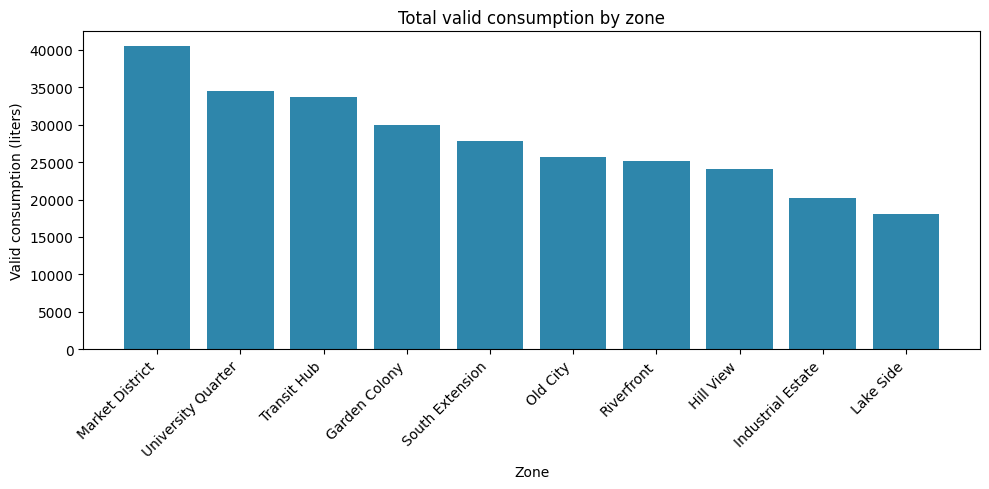

In [0]:
import matplotlib.pyplot as plt

zone_pdf = spark.sql("""
SELECT zone_name, SUM(consumption_liters) AS total_consumption
FROM water_valid_readings_view
GROUP BY zone_name
ORDER BY total_consumption DESC
""").toPandas()

plt.figure(figsize=(10, 5))
plt.bar(zone_pdf["zone_name"], zone_pdf["total_consumption"], color="#2E86AB")
plt.xticks(rotation=45, ha="right")
plt.xlabel("Zone")
plt.ylabel("Valid consumption (liters)")
plt.title("Total valid consumption by zone")
plt.tight_layout()
plt.show()

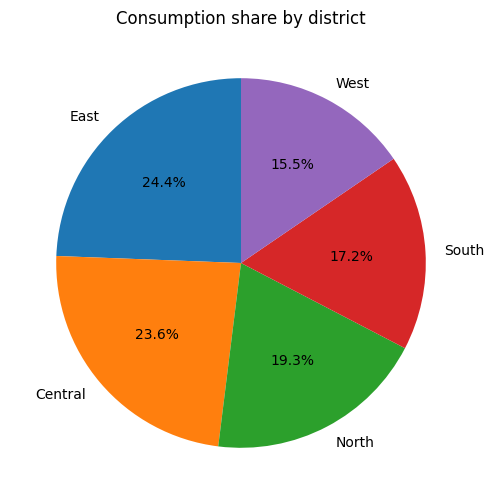

In [0]:
district_pdf = spark.sql("""
SELECT district, SUM(consumption_liters) AS total_consumption
FROM water_valid_readings_view
GROUP BY district
ORDER BY total_consumption DESC
""").toPandas()

plt.figure(figsize=(6, 6))
plt.pie(district_pdf["total_consumption"], labels=district_pdf["district"], autopct="%1.1f%%", startangle=90)
plt.title("Consumption share by district")
plt.show()

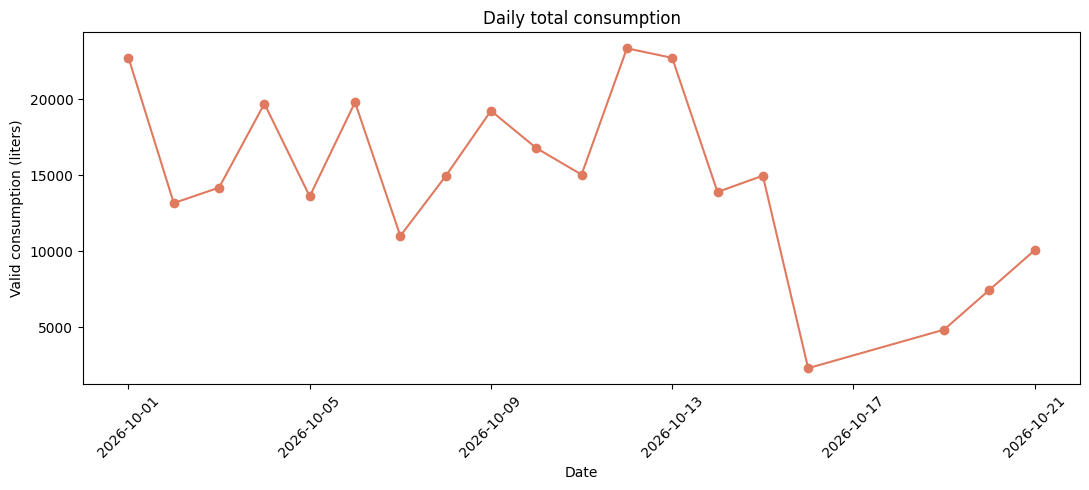

In [0]:
import pandas as pd

daily_pdf = spark.sql("""
SELECT CAST(reading_time AS DATE) AS reading_date, SUM(consumption_liters) AS total_consumption
FROM water_valid_readings_view
GROUP BY CAST(reading_time AS DATE)
ORDER BY reading_date
""").toPandas()
daily_pdf["reading_date"] = pd.to_datetime(daily_pdf["reading_date"])

plt.figure(figsize=(11, 5))
plt.plot(daily_pdf["reading_date"], daily_pdf["total_consumption"], marker="o", color="#E07A5F")
plt.xticks(rotation=45)
plt.xlabel("Date")
plt.ylabel("Valid consumption (liters)")
plt.title("Daily total consumption")
plt.tight_layout()
plt.show()

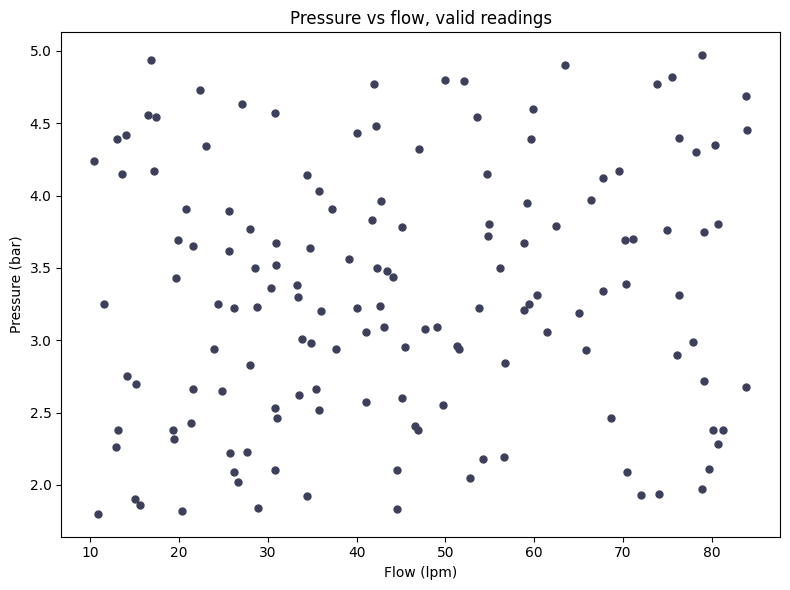

In [0]:
scatter_pdf = spark.sql("""
SELECT pressure_bar, flow_lpm FROM water_valid_readings_view WHERE pressure_bar IS NOT NULL
""").toPandas()

plt.figure(figsize=(8, 6))
plt.scatter(scatter_pdf["flow_lpm"], scatter_pdf["pressure_bar"], s=25, color="#3D405B")
plt.xlabel("Flow (lpm)")
plt.ylabel("Pressure (bar)")
plt.title("Pressure vs flow, valid readings")
plt.tight_layout()
plt.show()

In [0]:
%sql
WITH zone_metrics AS (
  SELECT zone_id, zone_name, district,
         SUM(consumption_liters) AS total_consumption,
         ROUND(AVG(pressure_bar), 2) AS avg_pressure,
         ROUND(AVG(chlorine_mg_l), 2) AS avg_chlorine,
         SUM(CASE WHEN pressure_bar < 2.5 THEN 1 ELSE 0 END) AS low_pressure_readings,
         SUM(CASE WHEN chlorine_mg_l < 0.3 OR chlorine_mg_l > 1.5 THEN 1 ELSE 0 END) AS chlorine_concerns
  FROM water_valid_readings_view
  GROUP BY zone_id, zone_name, district
),
request_metrics AS (
  SELECT zone_id,
         COUNT(*) AS service_requests,
         SUM(CASE WHEN priority = 'High' THEN 1 ELSE 0 END) AS high_priority_requests,
         SUM(CASE WHEN work_status <> 'Resolved' THEN 1 ELSE 0 END) AS unresolved_requests
  FROM water_service_requests
  GROUP BY zone_id
)
SELECT m.*, r.service_requests, r.high_priority_requests, r.unresolved_requests
FROM zone_metrics m
LEFT JOIN request_metrics r ON m.zone_id = r.zone_id
ORDER BY m.total_consumption DESC;

zone_id,zone_name,district,total_consumption,avg_pressure,avg_chlorine,low_pressure_readings,chlorine_concerns,service_requests,high_priority_requests,unresolved_requests
W03,Market District,Central,40465,3.06,0.83,6,1,3,1,2
W05,University Quarter,East,34577,3.45,0.79,2,0,4,1,3
W08,Transit Hub,East,33689,2.87,0.62,6,2,4,1,2
W07,Garden Colony,North,29994,3.42,0.74,1,2,3,1,2
W10,South Extension,South,27808,3.72,0.79,2,1,3,1,2
W01,Old City,Central,25677,3.38,0.83,3,1,4,2,3
W09,Riverfront,West,25154,3.38,0.69,2,1,4,1,2
W02,Hill View,North,24120,3.31,0.62,5,1,4,2,3
W06,Industrial Estate,South,20212,3.16,0.68,3,1,4,1,3
W04,Lake Side,West,18120,3.34,0.79,3,1,3,1,2
